<a href="https://colab.research.google.com/github/jsonwang2003/Shazam-from-Scratch/blob/main/%5BTEMPLATE%5D_Shazam_From_Scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Shazam from Scratch 🎵
**MAKE A COPY OF THIS FILE**
### HKN Workshop


> **The idea:** Shazam turns audio into a *constellation* of spectrogram peaks, hashes **pairs** of peaks into fingerprints, and identifies a song by finding the track whose fingerprints agree on **one consistent time offset**.

In about 25 minutes of coding you'll build a working audio fingerprinter that recognizes a noisy 5-second clip.

| Part | What you build | TODO |
|---|---|---|
| 1 | Spectrogram → **constellation map** of peaks | `find_peaks` |
| 2 | Hashes from **pairs** of peaks | `fingerprint` |
| 3 | Database + **offset voting** | `vote` |
| 4 | Stress test | (just run it) |

Most of the code is already written. Fill in the 3 **✏️ TODO** cells (and the corresponding ???'s) and run the ✅ check below each one. If you get stuck, open the *Stuck?* box and keep going.

Run cells top-to-bottom with **Shift+Enter**.

In [1]:
# Setup: run this first
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict, Counter
from scipy.signal import spectrogram, sosfiltfilt, butter, fftconvolve, resample
from scipy.ndimage import maximum_filter
from IPython.display import Audio, display

FS = 11025          # sample rate (Hz). Low on purpose so everything runs in seconds
NPERSEG = 1024      # FFT window length -> ~10.8 Hz per frequency bin
HOP = 512           # step between windows -> ~46 ms per time frame
FRAME_SEC = HOP / FS

# Plot style: quiet axes so the data stands out
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": "#0b0b0b",
    "xtick.color": GREY, "ytick.color": GREY,
    "axes.titlesize": 12, "axes.titleweight": "bold",
})

def play(x):
    """Show an audio player for signal x."""
    display(Audio(x, rate=FS, normalize=True))

print("Ready ✔")

Ready ✔


## 0 · Our music library

> Want real music? Set `USE_REAL_AUDIO = True`. Paste the `DRIVE_FOLDER_URL` and the songs will download automatically.

In [ ]:
USE_REAL_AUDIO = True
AUDIO_DIR = ""
SONG_SECONDS = 30

# 🔗 Google Drive folder (shared as "Anyone with the link")
# Downloaded on first run. "" = don't download.
DRIVE_FOLDER_URL = "https://drive.google.com/drive/folders/1-GIfW2Oj3FOTUDjKdI1wbzKg_1OMxpa0?usp=drive_link"

# 📱 Recording mode: set to the path of your own recording (e.g. "my_clip.wav")
# to identify it instead of a generated clip. None = use a generated clip.
RECORDING = None
RECORDING_SECONDS = 5     # how much of the recording to use, from its start

In [ ]:
# ----------------------------------
# Synthesized music generation (feel free to skip reading this cell)
# I don't understand the syntethic music generation either :(
# ----------------------------------

SONG_NAMES = ["Fourier Nights", "Nyquist Shuffle", "Aliasing Blues", "Phase-Locked Love",
              "Bode to Joy", "Lowpass Lullaby", "Eigen Groove", "Midnight Modem"]
SCALES = {"major": [0, 2, 4, 5, 7, 9, 11], "minor": [0, 2, 3, 5, 7, 8, 10],
          "pentatonic": [0, 2, 4, 7, 9], "dorian": [0, 2, 3, 5, 7, 9, 10]}

def _note(freq, dur, harmonics, decay):
    t = np.arange(int(dur * FS)) / FS
    vibrato = 1 + 0.003 * np.sin(2 * np.pi * 5 * t)
    y = sum(a * np.sin(2 * np.pi * freq * (k + 1) * t * vibrato) for k, a in enumerate(harmonics))
    return y * np.minimum(1, t / 0.01) * np.exp(-decay * t / dur)

def make_song(seed, seconds=SONG_SECONDS):
    rng = np.random.default_rng(seed)
    beat = 60 / rng.integers(80, 150)
    scale = np.array(SCALES[rng.choice(list(SCALES))])
    scale = np.concatenate([scale, scale + 12])
    root = rng.integers(45, 57)
    lead = rng.dirichlet(np.ones(5)) * rng.uniform(1, 2)      # per-song timbre
    pad = rng.dirichlet(np.ones(3))
    progression = rng.choice(len(scale) // 2, size=4)
    out = np.zeros(int((seconds + 2) * FS))
    t = 0.0
    while t < seconds:
        i = int(t * FS)
        # chord + bass on every beat
        deg = progression[int(t / (4 * beat)) % 4]
        for off in (0, 2, 4):
            f = 440 * 2 ** ((root + scale[deg + off] - 69) / 12)
            seg = 0.25 * _note(f, beat, pad, 2)
            out[i:i + len(seg)] += seg
        seg = 0.5 * _note(440 * 2 ** ((root - 12 + scale[deg] - 69) / 12), beat, [1, .4], 3)
        out[i:i + len(seg)] += seg
        # melody: random rhythm of 8th / 16th / quarter notes
        sub = 0.0
        while sub < beat - 1e-9:
            dur = beat * rng.choice([0.25, 0.5, 0.5, 1.0])
            if rng.random() > 0.15:
                f = 440 * 2 ** ((root + 12 + rng.choice(scale) - 69) / 12)
                seg = 0.6 * _note(f, dur, lead, 3)
                j = i + int(sub * FS)
                out[j:j + len(seg)] += seg
            sub += dur
        # hi-hat
        hh = rng.standard_normal(int(0.03 * FS)) * np.exp(-np.arange(int(0.03 * FS)) / (0.004 * FS))
        out[i:i + len(hh)] += 0.15 * hh
        t += beat
    out = out[:int(seconds * FS)]
    out += 10 ** (-30 / 20) * np.sqrt(np.mean(out ** 2)) * rng.standard_normal(len(out))  # faint hiss, like a real recording
    return out / np.abs(out).max()

This downloading step may take a minute or two...

In [ ]:
# ----------------------------------
# Load audio
# ----------------------------------
import importlib, subprocess, sys
from pathlib import Path

AUDIO_EXTS = {".wav", ".mp3", ".flac", ".ogg"}

def _require(package):
    """Import a package, installing it first if needed (Colab normally has these already)."""
    try:
        return importlib.import_module(package)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)
        return importlib.import_module(package)

def load_audio(path, seconds=SONG_SECONDS):
    """Load an audio file as mono at FS."""
    x, _ = _require("librosa").load(path, sr=FS, mono=True, duration=seconds)
    return x / (np.abs(x).max() + 1e-12)

def fetch_from_drive(url):
    """Download the shared Drive folder into the current folder, unless the songs are already here."""
    have_songs = Path(AUDIO_DIR).is_dir() and any(p.suffix.lower() in AUDIO_EXTS for p in Path(AUDIO_DIR).iterdir())
    if url and not have_songs:
        print("Downloading songs from Google Drive...")
        _require("gdown").download_folder(url, output=".", quiet=True)

if USE_REAL_AUDIO or RECORDING:
    fetch_from_drive(DRIVE_FOLDER_URL)

if USE_REAL_AUDIO:
    if not Path(AUDIO_DIR).is_dir():
        raise FileNotFoundError(f"No '{AUDIO_DIR}/' folder. Set DRIVE_FOLDER_URL, or upload your songs into '{AUDIO_DIR}/'.")
    files = sorted(p for p in Path(AUDIO_DIR).iterdir() if p.suffix.lower() in AUDIO_EXTS)
    if not files:
        raise FileNotFoundError(f"No {'/'.join(sorted(AUDIO_EXTS))} files in '{AUDIO_DIR}/'.")
    SONG_NAMES = [p.stem for p in files]
    songs = [load_audio(p) for p in files]
else:
    songs = [make_song(seed) for seed in range(len(SONG_NAMES))]

for i, name in enumerate(SONG_NAMES):
    print(f"  [{i}] {name}  ({len(songs[i]) / FS:.0f} s)")

  [0] Arcade Player - Coconut Mall (From _Mario Kart Wii_)  (30 s)
  [1] Backstreet Boys - I Want It That Way  (30 s)
  [2] FOALS - Wake Me Up [Official Music Video]  (30 s)
  [3] Far From Any Road  (30 s)
  [4] KPop Demon Hunters Cast - Golden  (30 s)
  [5] Martin Garrix - Animals  (30 s)
  [6] Michael Jackson - Human Nature  (30 s)
  [7] Michael Jackson - Smooth Criminal  (30 s)
  [8] Niko B - trespass coat feat. dexter in the newsagent  (30 s)
  [9] Rick Astley - Never Gonna Give You Up  (30 s)
  [10] Shakira - Waka Waka (This Time for Africa) (K-Mix)  (30 s)
  [11] The 1975 - About You  (30 s)
  [12] Vendredi sur Mer - Écoute chérie  (30 s)


In [ ]:
play(songs[0])   # 🎧 a masterpiece

### The query: a short, noisy, time-shifted clip

This is what a phone hears: **5 seconds** from **somewhere** in a song, buried in noise. `make_query` is the "mystery clip" generator we'll use all session.

> 📱 **Recording mode:** set `RECORDING` (in the settings cell at the top of Part 0) to a file you recorded on your phone, and that recording becomes the query instead. The song must be in the library, so use `USE_REAL_AUDIO = True` or record one of the synthetic songs as it plays.

In [ ]:
def add_noise(x, snr_db, rng=None):
    """Add white noise at a given signal-to-noise ratio (dB). 0 dB means noise is as loud as the music."""
    rng = np.random.default_rng(rng)
    noise = rng.standard_normal(len(x))
    noise *= np.sqrt(np.mean(x ** 2) / 10 ** (snr_db / 10) / np.mean(noise ** 2))
    return x + noise

def make_query(song_id, start_sec, seconds=5, snr_db=0, rng=None):
    start = int(start_sec * FS)
    return add_noise(songs[song_id][start:start + int(seconds * FS)], snr_db, rng)

if RECORDING is None:
    # A random song and start time: pretend we don't know these!
    SECRET_SONG = np.random.randint(len(songs))
    SECRET_START = round(np.random.uniform(0, len(songs[SECRET_SONG]) / FS - 5), 1)   # leave room for a 5 s clip
    query = make_query(SECRET_SONG, SECRET_START, snr_db=0, rng=0)
else:
    # Your recording: this time we really don't know the answer
    query = load_audio(RECORDING, seconds=RECORDING_SECONDS)
    SECRET_SONG, SECRET_START = None, None

SHOW_SONG = SECRET_SONG if SECRET_SONG is not None else 0   # song to plot next to the query
play(query)

---
## Part 1 · From audio to a constellation map

A **spectrogram** is a heatmap: time on x, frequency on y, color = energy (in dB). We compute it with a short-time FFT (Fast-Fourier Transform): 1024-sample windows that step forward 512 samples at a time.

S_song shape (freq bins, time frames): (513, 644)


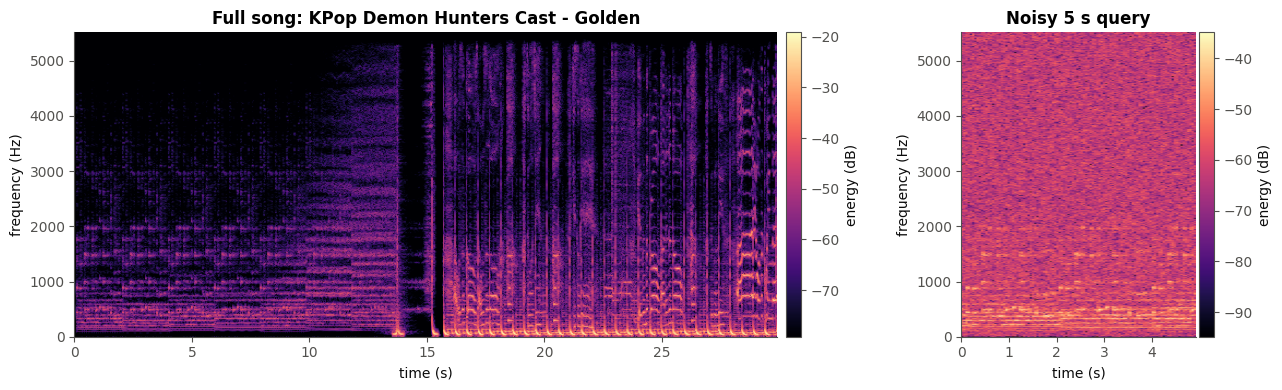

In [ ]:
def compute_spectrogram(x):
    """Returns (freqs_hz, times_sec, Spectrogram_db) where Spectrogram_db has shape (n_freq_bins, n_time_frames)."""
    f, t, S = spectrogram(x, fs=FS, nperseg=NPERSEG, noverlap=NPERSEG - HOP)
    return f, t, 10 * np.log10(S + 1e-10)

def plot_spectrogram(Spectrogram_db, title="", ax=None, peaks=None, max_hz=FS / 2):
    ax = ax or plt.gca()
    n_freq, n_time = Spectrogram_db.shape
    hz_per_bin = FS / NPERSEG
    vmax = Spectrogram_db.max()
    im = ax.imshow(Spectrogram_db, origin="lower", aspect="auto", cmap="magma", vmin=vmax - 60, vmax=vmax,
                   extent=[0, n_time * FRAME_SEC, 0, n_freq * hz_per_bin])
    ax.figure.colorbar(im, ax=ax, label="energy (dB)", pad=0.01)
    if peaks is not None and len(peaks):
        ax.scatter(peaks[:, 1] * FRAME_SEC, peaks[:, 0] * hz_per_bin, s=14, c=AQUA,
                   edgecolors="white", linewidths=0.6, label=f"{len(peaks)} peaks")
        ax.legend(loc="upper right", frameon=False)
    ax.set(ylim=(0, max_hz), xlabel="time (s)", ylabel="frequency (Hz)", title=title)

f, t, S_song = compute_spectrogram(songs[SHOW_SONG])
_, _, S_query = compute_spectrogram(query)
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [3, 1]})
plot_spectrogram(S_song, f"Full song: {SONG_NAMES[SHOW_SONG]}", axes[0])
plot_spectrogram(S_query, f"Noisy {len(query) / FS:.0f} s query", axes[1])
plt.tight_layout()
print("S_song shape (freq bins, time frames):", S_song.shape)

Notice how the noise fills in the background of the query, but the **bright spots** still stand out. Those bright spots are what we'll keep.

### ✏️ TODO 1: `find_peaks`

A point is a **peak** if it is
1. the **maximum of its neighborhood**, meaning no louder point within ±10 bins in frequency and ±10 frames in time, **and**
2. **loud enough**, meaning more than `threshold_db` above the spectrogram's mean, so quiet background bumps don't count.

Tools:
- `maximum_filter(Spectrogram_db, size=neighborhood)` returns an array where every pixel holds the max of its neighborhood. So `maximum_filter(Spectrogram_db, ...) == Spectrogram_db` returns the local maxima.
- `np.argwhere(mask)` returns the `(row, col)` = `(freq_idx, time_idx)` of every `True`.
- **Sort the peaks by time**, since Part 2 depends on it. `peaks[np.argsort(peaks[:, 1], kind="stable")]` does this.

In [ ]:
def find_peaks(Spectrogram_db, neighborhood=(20, 20), threshold_db=10):
    """Return an int array of shape (n_peaks, 2): columns are (freq_idx, time_idx), sorted by time."""
    # ✏️ TODO 1: your code here (about 4 lines)
    local_max = maximum_filter(Spectrogram_db, size=???) == Spectrogram_db
    loud = Spectrogram_db > ??? + ???
    # extract the points that are past the threshold and local maxima
    peaks = np.argwhere(local_max & loud)
    return peaks[np.argsort(peaks[:, 1], kind="stable")] # stable ensures we have a predictable way of handling duplicates


SyntaxError: invalid syntax (1361629.py, line 4)

<details><summary>😵 <b>Stuck?</b> Click to reveal the solution</summary>

```python
def find_peaks(Spectrogram_db, neighborhood=(20, 20), threshold_db=10):
    """Return an int array of shape (n_peaks, 2): columns are (freq_idx, time_idx), sorted by time."""
    local_max = maximum_filter(Spectrogram_db, size=neighborhood) == Spectrogram_db
    loud = Spectrogram_db > Spectrogram_db.mean() + threshold_db
    peaks = np.argwhere(local_max & loud)
    return peaks[np.argsort(peaks[:, 1], kind="stable")] # stable ensures we have a predictable way of handling duplicates

```
</details>

In [ ]:
# ✅ Check TODO 1
S_test = np.zeros((50, 60))
S_test[10, 10], S_test[12, 12], S_test[30, 40], S_test[40, 5] = 20, 15, 25, 30
got = find_peaks(S_test, neighborhood=(20, 20), threshold_db=10)
assert isinstance(got, np.ndarray) and got.ndim == 2 and got.shape[1] == 2, "return an (n, 2) array"
assert got.tolist() == [[40, 5], [10, 10], [30, 40]], f"expected [[40,5],[10,10],[30,40]] (sorted by time), got {got.tolist()}"

song_peaks = find_peaks(S_song)
query_peaks = find_peaks(S_query)
print(f"✅ find_peaks works! Song: {len(song_peaks)} peaks ({len(song_peaks) / SONG_SECONDS:.0f}/s), query: {len(query_peaks)} peaks")

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [3, 1]})
plot_spectrogram(S_song, "Constellation map: song", axes[0], peaks=song_peaks)
plot_spectrogram(S_query, "Constellation map: query", axes[1], peaks=query_peaks)
plt.tight_layout()

🌌 **That's the constellation map.** We've reduced 330,000 audio samples to a few hundred points, and these points are all we'll use from here on.

### Experiment: do peaks survive noise?

Below we add noise to the clean audio and check what fraction of the clean peaks still appear (within ±1 bin) in the noisy version. **Change `SNR_DB`** and re-run. Try 20, 10, 0, and −10.

In [ ]:
SNR_DB = 0      # 🔧 try 20, 0, -5, -10

clean = songs[SHOW_SONG][int(10 * FS):int(15 * FS)]
noisy = add_noise(clean, SNR_DB, rng=1)
p_clean = find_peaks(compute_spectrogram(clean)[2])
p_noisy = find_peaks(compute_spectrogram(noisy)[2])

noisy_set = {(fi + df, ti + dt) for fi, ti in p_noisy for df in (-1, 0, 1) for dt in (-1, 0, 1)}
survived = np.array([(fi, ti) in noisy_set for fi, ti in p_clean])

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
plot_spectrogram(compute_spectrogram(noisy)[2], f"Noisy audio ({SNR_DB} dB SNR)", axes[0])
hz, sec = FS / NPERSEG, FRAME_SEC
axes[1].scatter(p_clean[survived, 1] * sec, p_clean[survived, 0] * hz, s=18, c=BLUE, label="clean peak, survived")
axes[1].scatter(p_clean[~survived, 1] * sec, p_clean[~survived, 0] * hz, s=24, c=ORANGE, marker="x", label="clean peak, lost")
axes[1].set(xlabel="time (s)", title=f"{survived.mean():.0%} of clean peaks survive")
axes[1].legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout()

### 🗣 Discuss
- At 0 dB we lose a lot of peaks, mostly the weak high-frequency ones. The strong notes survive at **exactly the same** positions. Why? *(White noise spreads its energy across every bin; a note concentrates its energy in a few.)*
- Is **one peak** `(freq, time)` enough to identify a song? *(No. Each frequency appears in many songs, and `time` depends on where the clip started.)*

---
## Part 2 · Fingerprints: hashing *pairs* of peaks

A single peak isn't distinctive, but a **pair** of peaks is:

$$\text{hash} = (f_1,\; f_2,\; \Delta t), \qquad \Delta t = t_2 - t_1$$

This hash contains **no absolute time**, so it's the same whether the clip starts at 0:00 or 2:37. We store the anchor time $t_1$ *next to* the hash for later.

Each peak (the *anchor*) pairs only with the next `fan_out` peaks after it, rather than with every peak, which would be $O(n^2)$.

### ✏️ TODO 2: `fingerprint`
For each anchor `(f1, t1)` at index `i`, loop over the targets `peaks[i+1 : i+1+fan_out]`. For each target `(f2, t2)`, if `0 < dt <= max_dt`, append `((f1, f2, dt), t1)`.

Only keep positive ∆t's to ensure no duplicates.

In [ ]:
def fingerprint(peaks, fan_out=10, max_dt=200):
    """Return a list of (hash_key, anchor_time) where hash_key = (f1, f2, dt)."""
    hashes = []
    # ✏️ TODO 2: your code here (about 5 lines)
    for i, (f1, t1) in enumerate(peaks):
        for f2, t2 in peaks[i + 1:i + 1 + fan_out]:
            dt = ???
            if 0 < dt <= max_dt:
                ???

    return hashes

<details><summary>😵 <b>Stuck?</b> Click to reveal the solution</summary>

```python
def fingerprint(peaks, fan_out=10, max_dt=200):
    """Return a list of (hash_key, anchor_time) where hash_key = (f1, f2, dt)."""
    hashes = []
    for i, (f1, t1) in enumerate(peaks):
        for f2, t2 in peaks[i + 1:i + 1 + fan_out]:
            dt = t2 - t1
            if 0 < dt <= max_dt:
                hashes.append(((int(f1), int(f2), int(dt)), int(t1)))
    return hashes
```
</details>

In [ ]:
# ✅ Check TODO 2
toy_peaks = np.array([[10, 0], [20, 3], [15, 5], [30, 400]])
got = fingerprint(toy_peaks, fan_out=2, max_dt=200)
expected = [((10, 20, 3), 0), ((10, 15, 5), 0), ((20, 15, 2), 3)]
assert sorted(got) == sorted(expected), f"expected {expected}\n got      {got}"

query_hashes = fingerprint(query_peaks)
print(f"✅ fingerprint works! The query has {len(query_hashes)} hashes, e.g. {query_hashes[:2]}")

# Visualize the anchor -> target-zone pairs for a few anchors
fig, ax = plt.subplots(figsize=(11, 4))
plot_spectrogram(S_query, "Anchor peaks (blue) paired with their fan-out targets", ax)
ax.scatter(query_peaks[:, 1] * FRAME_SEC, query_peaks[:, 0] * FS / NPERSEG, s=10, c=AQUA, alpha=0.5)
for i in range(0, len(query_peaks), max(1, len(query_peaks) // 6))[:6]:
    f1, t1 = query_peaks[i]
    for f2, t2 in query_peaks[i + 1:i + 11]:
        ax.plot(np.array([t1, t2]) * FRAME_SEC, np.array([f1, f2]) * FS / NPERSEG, c=ORANGE, lw=1, alpha=0.8)
    ax.scatter([t1 * FRAME_SEC], [f1 * FS / NPERSEG], s=60, c=BLUE, edgecolors="white", zorder=3)

---
## Part 3 · The database and offset voting

The database is an **inverted index**: a dict mapping **hash → list of (song_id, t_anchor)**. A lookup takes O(1) time no matter how many songs are stored. This cell builds it for the whole library:

In [ ]:
def build_database(songs):
    db = defaultdict(list)
    for song_id, x in enumerate(songs):
        for key, t_anchor in fingerprint(find_peaks(compute_spectrogram(x)[2])):
            db[key].append((song_id, t_anchor))
    return db

db = build_database(songs)
print(f"{len(db):,} distinct hashes, {sum(len(v) for v in db.values()):,} entries for {len(songs)} songs")

### The key idea: real matches agree on a time offset

Suppose a query hash at time $t_q$ matches a song hash at time $t_s$. For a **real** match, $t_s - t_q$ is where the clip starts in the song, and that value is **the same for every real match**. Coincidental matches (songs share notes!) produce random offsets.

So each matching hash **votes** for `(song_id, offset)`, and the tallest pile of votes wins.

### ✏️ TODO 3: `vote`
For each `(key, t_q)` in the query, and for each `(song_id, t_s)` in `db.get(key, [])`, add one vote to `votes[song_id][t_s - t_q]`.

*(`votes[song_id]` is a `Counter`, so `+= 1` just works.)*

In [ ]:
def vote(query_hashes, db):
    """Return {song_id: Counter({offset: n_votes})}."""
    votes = defaultdict(Counter)
    # ✏️ TODO 3: your code here (about 3 lines)
    for key, t_q in query_hashes:
        for song_id, t_s in db.get(key, []):
            ???

    return votes

<details><summary>😵 <b>Stuck?</b> Click to reveal the solution</summary>

```python
def vote(query_hashes, db):
    """Return {song_id: Counter({offset: n_votes})}."""
    votes = defaultdict(Counter)
    for key, t_q in query_hashes:
        for song_id, t_s in db.get(key, []):
            votes[song_id][t_s - t_q] += 1
    return votes
```
</details>

> Why do we do `votes[song_id][t_s - t_q]` instead of doing the scatterplot of query-song matches and finding diagonal line?

This is essentially the same thing, the idea is that if two songs are the same, the sample and query should match pretty frequently for the same `t_s - t_q` since the offset will remain constant between the song and query sample.

In [ ]:
# ✅ Check TODO 3
toy_db = {(1, 2, 3): [(0, 10), (1, 99)], (4, 5, 6): [(0, 11)]} # each (f_1, f_2, ∆t) is as good as a hashed version of it in this dict
toy_votes = vote([((1, 2, 3), 5), ((4, 5, 6), 6)], toy_db)
assert toy_votes[0] == Counter({5: 2}) and toy_votes[1] == Counter({94: 1}), dict(toy_votes)
print("✅ vote works!")

def identify(clip):
    """Full pipeline: audio -> peaks -> hashes -> votes -> ranked [(song_id, score, offset_sec)]."""
    votes = vote(fingerprint(find_peaks(compute_spectrogram(clip)[2])), db)
    ranked = [(sid, *reversed(c.most_common(1)[0])) for sid, c in votes.items()]
    return sorted(((sid, score, off * FRAME_SEC) for sid, score, off in ranked), key=lambda r: -r[1])

ranked = identify(query)
song_id, score, offset = ranked[0]
print(f"\n🎵 It's '{SONG_NAMES[song_id]}', starting at {offset:.1f} s   (score {score})")
if SECRET_SONG is not None:
    print(f"   truth: '{SONG_NAMES[SECRET_SONG]}' at {SECRET_START} s")

### 💡 Why it works

**Left:** each matching hash plotted at (query time, song time). For the true song, the real matches fall on a **diagonal**. **Right:** the histogram of `t_s − t_q`, where that diagonal becomes **one spike**.

In [ ]:
def plot_match(clip, song_ids, labels, true_offset=None):
    q_hashes = fingerprint(find_peaks(compute_spectrogram(clip)[2]))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
    if true_offset is not None:
        qt = np.array([0, len(clip) / FS])
        ax1.plot(qt, qt + true_offset, ls="--", lw=1, c=GREY, label=f"t_song = t_query + {true_offset:.1f} s")
    for sid, color, label in zip(song_ids, [BLUE, ORANGE], labels):
        pts = np.array([(t_q, t_s) for key, t_q in q_hashes
                        for s, t_s in db.get(key, []) if s == sid]) * FRAME_SEC
        if len(pts) == 0:
            continue
        ax1.scatter(pts[:, 0], pts[:, 1], s=16, c=color, alpha=0.7, label=label)
        ax2.hist(pts[:, 1] - pts[:, 0], bins=np.arange(-6, SONG_SECONDS + 1, 0.25), color=color, alpha=0.75, label=label)
    ax1.set(xlabel="time in query (s)", ylabel="time in song (s)", title="Matching hashes")
    ax2.set(xlabel="offset  t_song − t_query  (s)", ylabel="# matching hashes", title="Offset histogram")
    for ax in (ax1, ax2):
        ax.legend(frameon=False)
    plt.tight_layout()

# With a recording we don't know the truth, so compare the best match against the runner-up
true_song = SECRET_SONG if SECRET_SONG is not None else ranked[0][0]
true_offset = SECRET_START if SECRET_START is not None else ranked[0][2]
kind = "true song" if SECRET_SONG is not None else "best match"
ids, labels = [true_song], [f"{kind}: {SONG_NAMES[true_song]}"]
wrong = next((sid for sid, _, _ in ranked if sid != true_song), None)   # best-scoring other song, if any
if wrong is not None:
    ids.append(wrong)
    labels.append(f"wrong song: {SONG_NAMES[wrong]}")
plot_match(query, ids, labels, true_offset=true_offset)

### 🗣 Discuss
- The wrong song also has some hash hits. Why don't they matter? *(They don't **agree** on an offset. Alignment is the evidence, not the hit count.)*
- Why does the true song have a few smaller spikes too? *(Music repeats: a chorus produces the same hashes at different times.)*

### 🗣 Discuss
- The algorithm *always* returns a best guess. Looking at the scores, how would you decide to answer **"no match"**?
- Why does a 5% speed-up break it completely? *(Every frequency bin and every Δt shifts, so no hash matches exactly.)*

**🔧 If you finish early:** find the noise level or clip length where it breaks, or record a song from this notebook on your phone, upload it, set `RECORDING` at the top, and re-run everything (or just run `identify(load_audio("your_file.wav", seconds=10))`).

---
## Wrap-up

```
audio → spectrogram → peaks → peak-pair hashes (f1, f2, Δt) → inverted index
query → hashes → look up → vote on (song, t_song − t_query) → tallest spike wins
```

Real Shazam does the same thing at scale: it packs hashes into 32-bit ints and shards the index across machines. Read the original 4-page paper: Avery Wang, [*An Industrial-Strength Audio Search Algorithm*](https://www.ee.columbia.edu/~dpwe/papers/Wang03-shazam.pdf), ISMIR 2003.